# 01a — Exploratory Data Analysis (VisDrone video detection)

Statistics of the competition annotations (56 train videos, 7 validation videos) that guide the choices of input resolution, anchors, sampling, validation split and the handling of ignored regions in the later notebooks. Runs on CPU (Kaggle with the competition data attached, or Colab with `visdrone_competition.zip` on Drive).

In [1]:
from pathlib import Path
import json, zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Runs on CPU. Kaggle: competition data attached. Colab: only the two annotation files (and the
# few images shown below) are extracted from visdrone_competition.zip on Google Drive.
KAGGLE_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
ZIP = None
if KAGGLE_ROOT.exists():
    DATA_ROOT = KAGGLE_ROOT
else:
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP = Path("/content/drive/MyDrive/UCU_AI_HW2/visdrone_competition.zip")
    base = Path("/content/visdrone_eda")
    with zipfile.ZipFile(ZIP) as z:
        names = z.namelist()
        for n in names:
            if n.endswith(("train/annotations_coco.json", "val/annotations_coco.json")):
                z.extract(n, base)
    DATA_ROOT = next(base.rglob("train/annotations_coco.json")).parent.parent
    ZIP_PREFIX = next(n for n in names if n.endswith("train/annotations_coco.json"))[:-len("train/annotations_coco.json")]

print("Dataset root:", DATA_ROOT)
print("Train annotations:", (DATA_ROOT / "train/annotations_coco.json").exists())
print("Validation annotations:", (DATA_ROOT / "val/annotations_coco.json").exists())

Mounted at /content/drive
Dataset root: /content/visdrone_eda
Train annotations: True
Validation annotations: True


In [2]:
with open(DATA_ROOT / "train/annotations_coco.json") as f:
    train_coco = json.load(f)

with open(DATA_ROOT / "val/annotations_coco.json") as f:
    val_coco = json.load(f)

print("TRAIN")
print("Images:", len(train_coco["images"]))
print("Annotations:", len(train_coco["annotations"]))
print("Categories:", train_coco["categories"])

print("\nVALIDATION")
print("Images:", len(val_coco["images"]))
print("Annotations:", len(val_coco["annotations"]))

TRAIN
Images: 24201
Annotations: 1616260
Categories: [{'id': 1, 'name': 'person'}, {'id': 2, 'name': 'bicycle'}, {'id': 3, 'name': 'car'}, {'id': 4, 'name': 'van'}, {'id': 5, 'name': 'truck'}, {'id': 6, 'name': 'tricycle'}, {'id': 7, 'name': 'bus'}, {'id': 8, 'name': 'motor'}]

VALIDATION
Images: 2846
Annotations: 146092


In [3]:
CLASSES = [
    "person", "bicycle", "car", "van",
    "truck", "tricycle", "bus", "motor"
]

def coco_to_dataframe(coco, split):
    images = {img["id"]: img for img in coco["images"]}
    rows = []

    for ann in coco["annotations"]:
        img = images[ann["image_id"]]
        x, y, w, h = ann["bbox"]

        rows.append({
            "split": split,
            "image_id": ann["image_id"],
            "file_name": img["file_name"],
            "clip": img.get("video", img["file_name"].split("/")[0]),
            "class_id": ann["category_id"] - 1,
            "iscrowd": ann.get("iscrowd", 0),
            "x": x,
            "y": y,
            "width": w,
            "height": h,
            "area": w * h,
            "image_width": img["width"],
            "image_height": img["height"],
        })

    return pd.DataFrame(rows)

train_df = coco_to_dataframe(train_coco, "train")
val_df = coco_to_dataframe(val_coco, "val")

df = pd.concat([train_df, val_df], ignore_index=True)

# Для статистики класів виключаємо ignored regions
objects = df[(df["iscrowd"] == 0) &
             (df["class_id"].between(0, 7))].copy()

objects["class_name"] = objects["class_id"].map(
    dict(enumerate(CLASSES))
)

print("Total valid objects:", len(objects))
print("Ignored annotations:", (df["iscrowd"] == 1).sum())

display(objects.head())

Total valid objects: 1219648
Ignored annotations: 542704


,split,image_id,file_name,clip,class_id,iscrowd,x,y,width,height,area,image_width,image_height,class_name
0,train,1,images/uav0000013_00000_v/0000001.jpg,uav0000013_00000_v,0,0,424,543,35,88,3080,1344,756,person
1,train,1,images/uav0000013_00000_v/0000001.jpg,uav0000013_00000_v,0,0,416,530,36,85,3060,1344,756,person
2,train,1,images/uav0000013_00000_v/0000001.jpg,uav0000013_00000_v,5,0,531,641,87,114,9918,1344,756,tricycle
3,train,1,images/uav0000013_00000_v/0000001.jpg,uav0000013_00000_v,0,0,591,422,32,79,2528,1344,756,person
4,train,1,images/uav0000013_00000_v/0000001.jpg,uav0000013_00000_v,0,0,454,413,21,48,1008,1344,756,person


## Class Distribution

Number of annotated objects of the eight target classes in the train and validation videos (ignored regions excluded).

split,train,val
class_name,,
person,328701,50312
bicycle,40255,6022
car,505301,31821
van,46940,6842
truck,30498,1359
tricycle,41349,5487
bus,9653,264
motor,102819,12025


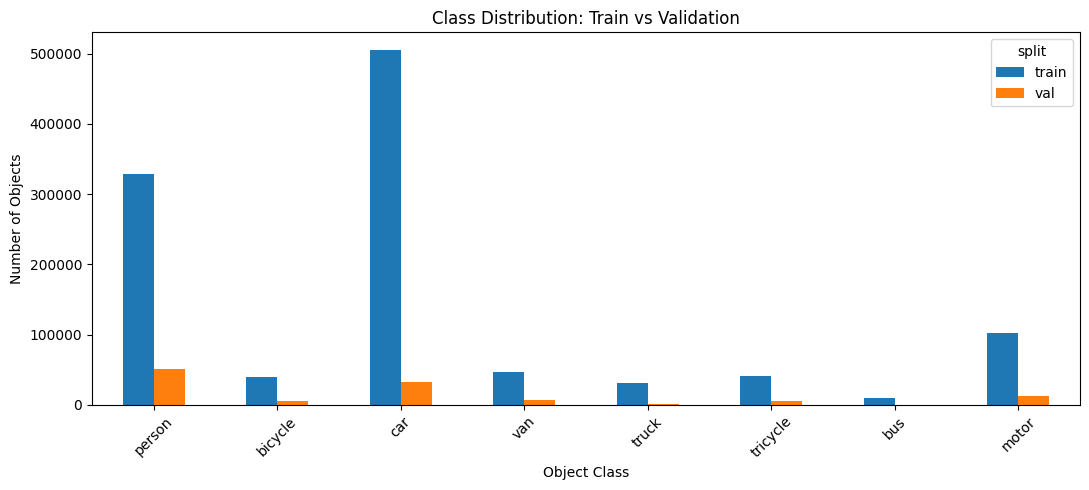

In [4]:
class_counts = pd.crosstab(
    objects["class_name"],
    objects["split"]
).reindex(CLASSES, fill_value=0)

display(class_counts)

class_counts.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Class Distribution: Train vs Validation")
plt.xlabel("Object Class")
plt.ylabel("Number of Objects")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observations**
- Strong imbalance: car (537k) and person (379k) make up 75 % of all objects, while bus has only 9.9k (≈ 54× fewer than car) and truck 31.9k.
- Class proportions differ between splits: car is 45 % of train objects but only 28 % of validation objects, person 29 % vs 44 %. Only 264 buses appear in validation, so the bus AP on the holdout is noisy.

## Object Size Distribution

Boxes are grouped into the COCO size categories used by AP_small / AP_medium / AP_large (small < 32², medium 32²–96², large ≥ 96² px), measured in original image coordinates (frames are mostly 1344×756).

,count
size_category,
Medium,781361
Small,297257
Large,141030


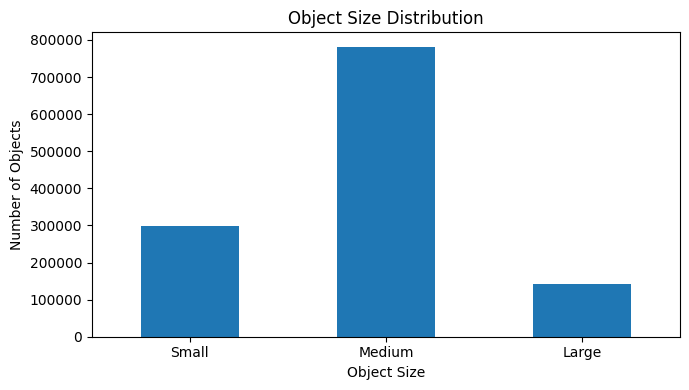


Median box dimensions:
width       44.0
height      49.0
area      2150.0
dtype: float64


In [5]:
objects["size_category"] = pd.cut(
    objects["area"],
    bins=[0, 32**2, 96**2, float("inf")],
    labels=["Small", "Medium", "Large"],
    right=False
)

size_counts = objects["size_category"].value_counts()

display(size_counts)

plt.figure(figsize=(7, 4))
size_counts.reindex(
    ["Small", "Medium", "Large"]
).plot(kind="bar")

plt.title("Object Size Distribution")
plt.xlabel("Object Size")
plt.ylabel("Number of Objects")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

print("\nMedian box dimensions:")
print(objects[["width", "height", "area"]].median())

**Observations**
- 24 % of objects are small, 64 % medium, 12 % large; the median box is only 44×49 px.
- Downscaling the frames (e.g. RT-DETR at 640×640, ≈ 2× smaller) turns many medium objects into small ones, so the input resolution matters for this dataset.

## Object Density and Sequence Analysis

Number of annotated objects per frame, the densest videos, and a check that the train and validation videos do not overlap.

,object_count
count,27047.000000
mean,45.093652
std,31.146503
min,0.000000
25%,21.000000
50%,42.000000
75%,57.000000
max,180.000000


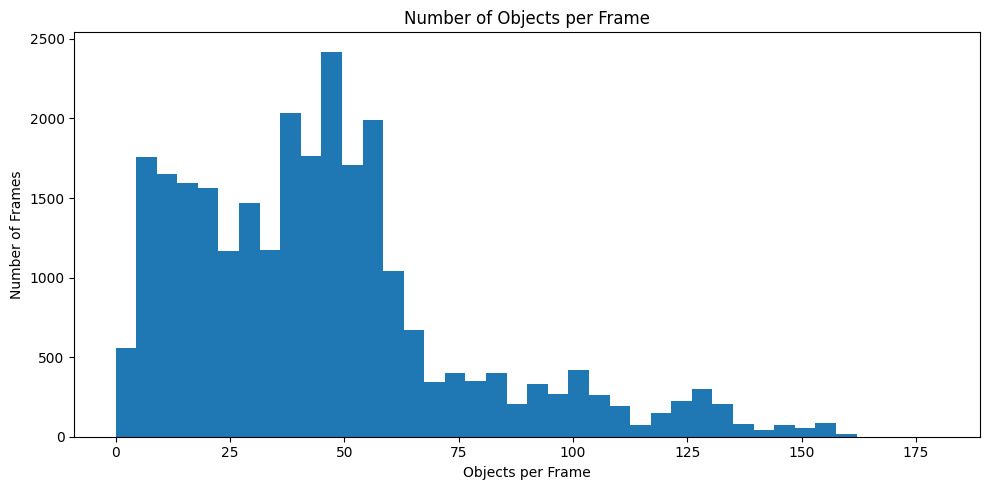

In [6]:
def image_table(coco, split):
    return pd.DataFrame([
        {
            "split": split,
            "image_id": img["id"],
            "file_name": img["file_name"],
            "clip": img.get(
                "video", img["file_name"].split("/")[0]
            )
        }
        for img in coco["images"]
    ])

images_df = pd.concat([
    image_table(train_coco, "train"),
    image_table(val_coco, "val")
], ignore_index=True)

frame_counts = (
    objects.groupby(["split", "image_id"])
    .size()
    .rename("object_count")
    .reset_index()
)

frames_df = images_df.merge(
    frame_counts,
    on=["split", "image_id"],
    how="left"
)

frames_df["object_count"] = (
    frames_df["object_count"].fillna(0).astype(int)
)

display(frames_df["object_count"].describe())

plt.figure(figsize=(10, 5))
plt.hist(frames_df["object_count"], bins=40)

plt.title("Number of Objects per Frame")
plt.xlabel("Objects per Frame")
plt.ylabel("Number of Frames")
plt.tight_layout()
plt.show()

In [7]:
clip_stats = (
    frames_df.groupby(["split", "clip"])
    .agg(
        frames=("image_id", "count"),
        avg_objects=("object_count", "mean"),
        max_objects=("object_count", "max")
    )
    .reset_index()
)

display(
    clip_stats.sort_values(
        "avg_objects", ascending=False
    ).head(15)
)

train_clips = set(
    images_df.loc[images_df["split"] == "train", "clip"]
)

val_clips = set(
    images_df.loc[images_df["split"] == "val", "clip"]
)

overlap = train_clips & val_clips

print("Train clips:", len(train_clips))
print("Validation clips:", len(val_clips))
print("Overlapping clips:", len(overlap))
print("Overlap:", overlap)

,split,clip,frames,avg_objects,max_objects
14,train,uav0000138_00000_v,213,142.962441,156
13,train,uav0000126_00001_v,412,132.218447,166
12,train,uav0000124_00944_v,398,124.567839,134
5,train,uav0000072_04488_v,85,110.376471,124
18,train,uav0000150_02310_v,348,108.885057,174
58,val,uav0000137_00458_v,233,103.381974,116
33,train,uav0000279_00001_v,547,95.347349,126
51,train,uav0000357_00920_v,691,91.891462,104
7,train,uav0000072_06432_v,97,89.948454,113
53,train,uav0000361_02323_v,219,85.803653,94


Train clips: 56
Validation clips: 7
Overlapping clips: 0
Overlap: set()


**Observations**
- 45 objects per frame on average (median 42), up to 180; the densest videos average 100–143 objects per frame.
- No video appears in both train and validation (56 vs 7 videos). Consecutive frames of a video are almost identical, so all splits are made by video and frames are subsampled (every 3rd–6th frame).

## Ground Truth Visualization

COCO boxes drawn on one training and one validation frame: green = target objects, red = ignored regions. Used to check the annotation conversion and to see typical small, overlapping and dense objects.

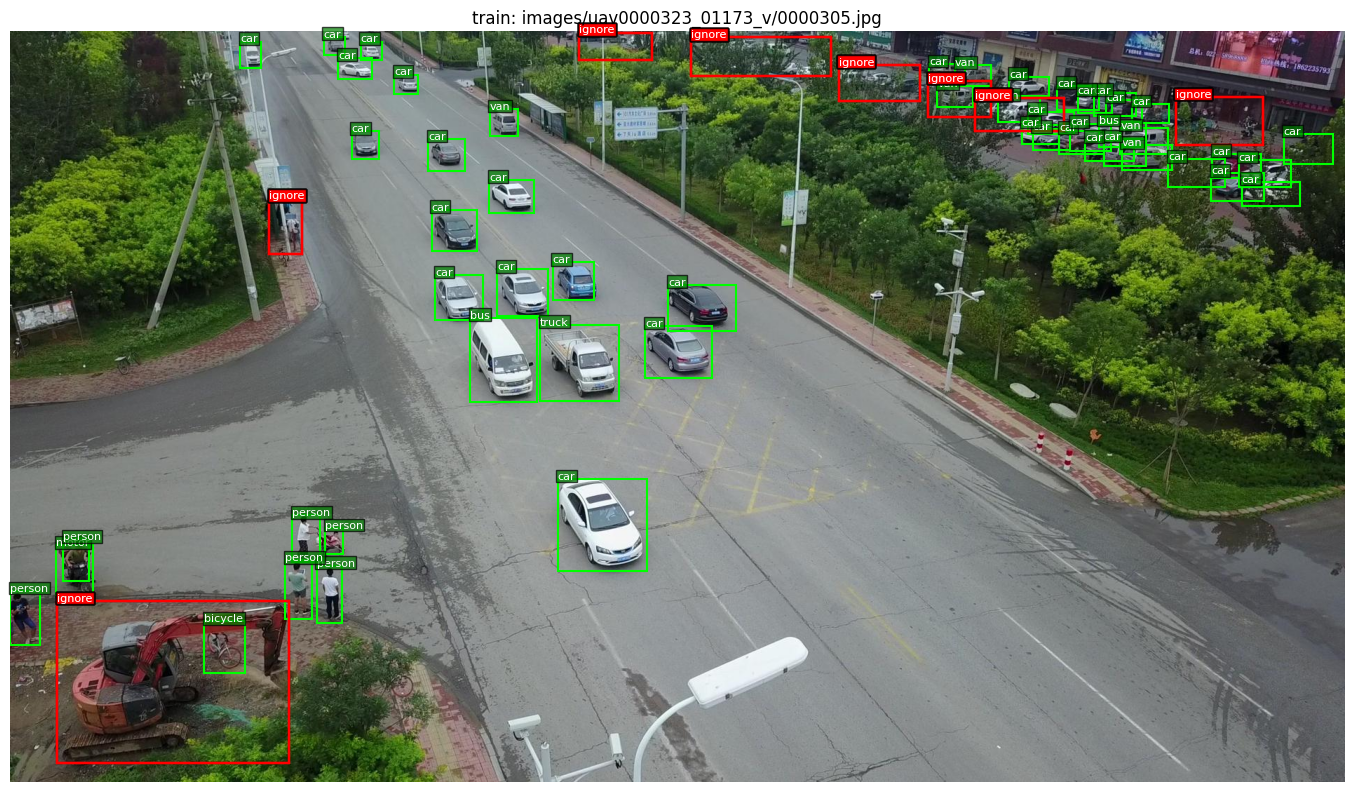

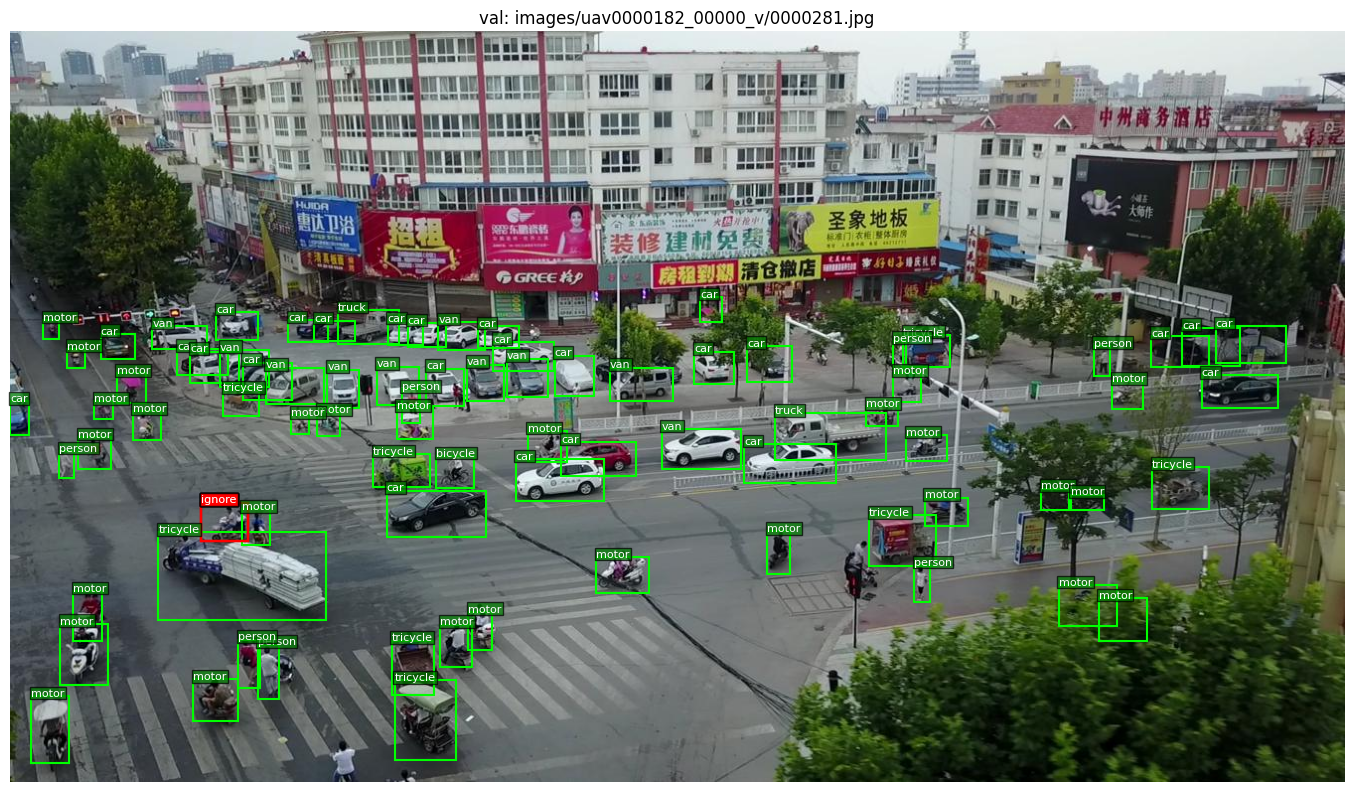

In [8]:
import random
from PIL import Image
from matplotlib.patches import Rectangle

def visualize_frame(coco, split="train", seed=42):
    rng = random.Random(seed)
    img_info = rng.choice(coco["images"])

    file_name = img_info["file_name"]

    # Підтримуємо різні варіанти шляхів у COCO
    candidates = [
        DATA_ROOT / split / "images" / file_name,
        DATA_ROOT / split / file_name,
        DATA_ROOT / file_name
    ]

    image_path = next(
        (p for p in candidates if p.exists()),
        None
    )

    if image_path is None and ZIP is not None:      # Colab: extract just this frame from the ZIP
        with zipfile.ZipFile(ZIP) as z:
            for rel in (f"{split}/{file_name}", f"{split}/images/{file_name}"):
                if ZIP_PREFIX + rel in z.NameToInfo:
                    z.extract(ZIP_PREFIX + rel, base)
        image_path = next((p for p in candidates if p.exists()), None)

    if image_path is None:
        print("Image not found:", file_name)
        print("Tried:", candidates)
        return

    image = Image.open(image_path).convert("RGB")

    annotations = [
        ann for ann in coco["annotations"]
        if ann["image_id"] == img_info["id"]
    ]

    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(image)

    for ann in annotations:
        x, y, w, h = ann["bbox"]
        ignored = ann.get("iscrowd", 0) == 1

        rect = Rectangle(
            (x, y), w, h,
            linewidth=1.5,
            edgecolor="red" if ignored else "lime",
            facecolor="none"
        )
        ax.add_patch(rect)

        if not ignored and 1 <= ann["category_id"] <= 8:
            label = CLASSES[ann["category_id"] - 1]
        else:
            label = "ignore"

        ax.text(
            x, y, label,
            color="white",
            fontsize=8,
            bbox=dict(
                facecolor="red" if ignored else "green",
                alpha=0.7,
                pad=1
            )
        )

    ax.set_title(f"{split}: {file_name}")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

visualize_frame(train_coco, "train", seed=42)
visualize_frame(val_coco, "val", seed=7)

## Variation Across Videos and Classes

Per-video statistics (density, share of small objects, median object area, most frequent class) and object size per class.

,frames,objects_per_frame,small_share,median_area
mean,429.32,49.13,0.21,2834.91
min,58.00,5.15,0.00,600.00
50%,363.00,44.19,0.18,2312.00
max,1424.00,142.96,0.73,7538.00


,objects,small_share,median_area,dominant_class,frames,objects_per_frame
video,,,,,,
uav0000086_00000_v,23097,0.29,1586.0,person,464,49.78
uav0000117_02622_v,17279,0.08,4240.0,person,349,49.51
uav0000137_00458_v,24088,0.01,5356.0,person,233,103.38
uav0000182_00000_v,17671,0.49,1053.0,motor,363,48.68
uav0000268_05773_v,13578,0.14,2345.0,car,978,13.88
uav0000305_00000_v,6391,0.11,5936.0,car,184,34.73
uav0000339_00001_v,12028,0.21,2356.0,person,275,43.74


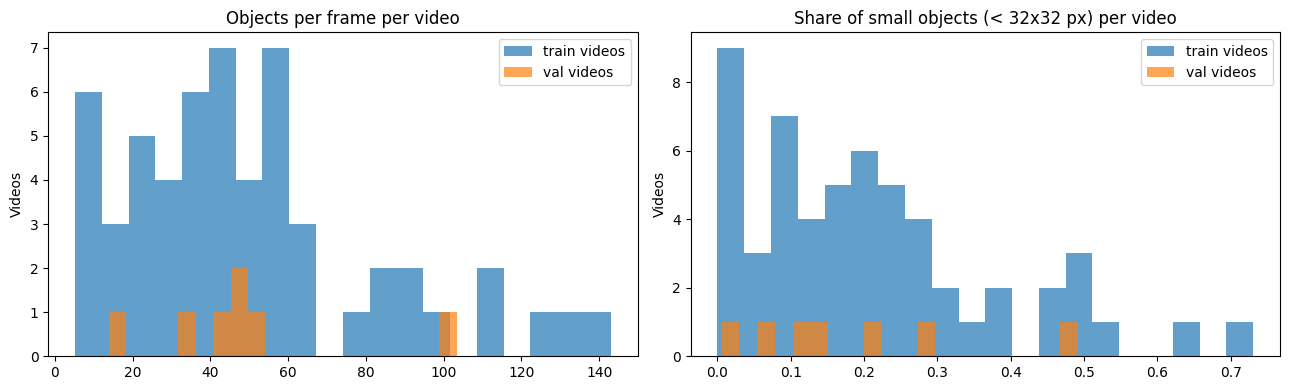

In [9]:
# Per-video statistics: density, share of small objects and dominant class
objects["video"] = objects["file_name"].map(lambda s: Path(s).parent.name)
frames_per_video = (pd.DataFrame([{"split": s, "video": Path(i["file_name"]).parent.name}
                                  for s, c in (("train", train_coco), ("val", val_coco)) for i in c["images"]])
                    .groupby(["split", "video"]).size().rename("frames"))
video_stats = objects.groupby(["split", "video"]).agg(
    objects=("area", "size"),
    small_share=("area", lambda a: (a < 32 ** 2).mean()),
    median_area=("area", "median"),
    dominant_class=("class_name", lambda c: c.value_counts().index[0]))
video_stats = video_stats.join(frames_per_video)
video_stats["objects_per_frame"] = video_stats["objects"] / video_stats["frames"]
display(video_stats[["frames", "objects_per_frame", "small_share", "median_area", "dominant_class"]]
        .describe().loc[["mean", "min", "50%", "max"]].round(2))
display(video_stats.loc["val"].round(2))          # the 7 holdout videos

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title in ((axes[0], "objects_per_frame", "Objects per frame"),
                       (axes[1], "small_share", "Share of small objects (< 32x32 px)")):
    ax.hist(video_stats.loc["train", col], bins=20, alpha=0.7, label="train videos")
    ax.hist(video_stats.loc["val", col], bins=20, alpha=0.7, label="val videos")
    ax.set_title(title + " per video"); ax.set_ylabel("Videos"); ax.legend()
plt.tight_layout(); plt.show()

,count,median_width,median_height,small_share
class_name,,,,
person,379013,26.0,51.0,0.38
bicycle,46277,47.0,45.0,0.22
car,537122,68.0,48.0,0.16
van,53782,57.0,47.0,0.19
truck,31857,81.0,69.0,0.09
tricycle,46836,58.0,51.0,0.21
bus,9917,123.0,103.0,0.04
motor,114844,37.0,43.0,0.31


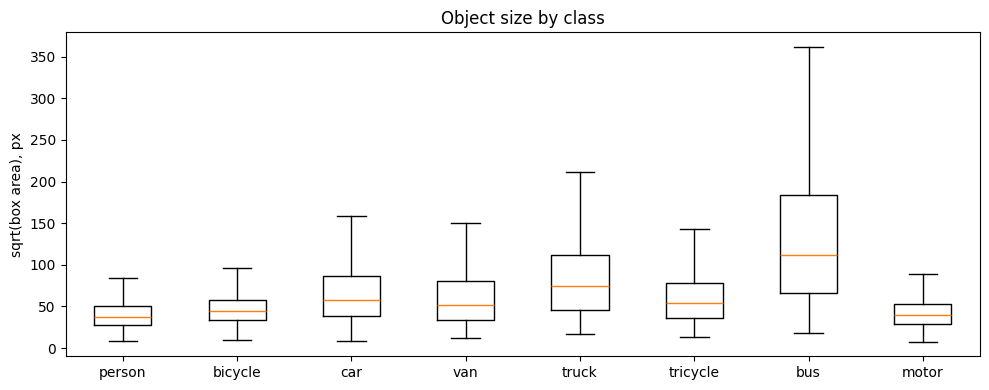

In [10]:
# Object size per class: rare classes (bus, truck) are also the largest, person and motor the smallest
size_by_class = objects.groupby("class_name").agg(
    count=("area", "size"),
    median_width=("width", "median"),
    median_height=("height", "median"),
    small_share=("area", lambda a: (a < 32 ** 2).mean())).reindex(CLASSES)
display(size_by_class.round(2))

plt.figure(figsize=(10, 4))
plt.boxplot([np.sqrt(objects.loc[objects.class_name == c, "area"]) for c in CLASSES],
            tick_labels=CLASSES, showfliers=False)
plt.ylabel("sqrt(box area), px"); plt.title("Object size by class")
plt.tight_layout(); plt.show()

**Observations**
- Videos differ strongly: 5 to 143 objects per frame and 0 % to 73 % small objects per video.
- The 7 holdout videos cover very different conditions: uav0000137 is dense (103 objects/frame) with almost no small objects (1 %), uav0000182 has 49 % small objects and mostly motorbikes, uav0000268 is sparse (14 objects/frame). Holdout scores therefore vary a lot between videos, which is why results are also reported on two halves of the holdout.
- Person (median 26×51 px, 38 % small) and motor (31 % small) are the smallest classes; bus (123×103 px, 4 % small) and truck are the largest but rarest.

## Ignored Regions Analysis

Ignored regions (`iscrowd = 1`) mark areas where objects are present but not annotated, so they should not be treated as ordinary background. Statistics on every 6th training frame.

In [11]:
# Every 6th frame of each training video (same subset as the YOLO notebook) for the ignored-region statistics
FRAME_STEP = 6
_tr = pd.DataFrame([{'image_id': i['id'], 'file_name': i['file_name'], 'clip': Path(i['file_name']).parent.name}
                    for i in train_coco['images']]).sort_values(['clip', 'file_name'])
sampled_train = _tr[_tr.groupby('clip').cumcount() % FRAME_STEP == 0].reset_index(drop=True)

Sampled frames: 4062
Ignored annotations: 85736
Frames with ignored regions: 3034
Percentage of affected frames: 74.69 %

Ignored region relative area:
count    85736.000000
mean         0.009139
std          0.013938
min          0.000103
25%          0.001949
50%          0.004398
75%          0.010140
max          0.146631
Name: relative_area, dtype: float64


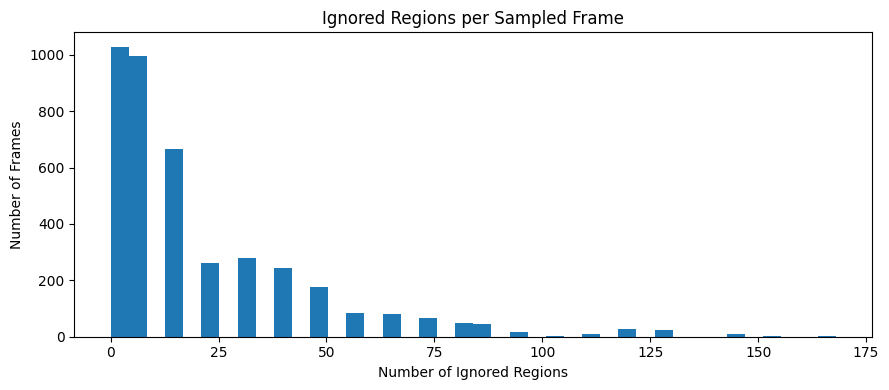

In [12]:

# Ignored regions in the sampled training subset

sampled_ids = set(sampled_train["image_id"])

sampled_annotations = train_df[
    train_df["image_id"].isin(sampled_ids)
].copy()

ignored = sampled_annotations[
    sampled_annotations["iscrowd"] == 1
].copy()

# Fraction of frame area covered by each ignored box
ignored["relative_area"] = (
    ignored["area"] /
    (ignored["image_width"] * ignored["image_height"])
)

ignored_per_frame = (
    ignored.groupby("image_id")
    .size()
    .reindex(sampled_train["image_id"], fill_value=0)
)

print("Sampled frames:", len(sampled_train))
print("Ignored annotations:", len(ignored))

print(
    "Frames with ignored regions:",
    (ignored_per_frame > 0).sum()
)

print(
    "Percentage of affected frames:",
    round((ignored_per_frame > 0).mean() * 100, 2),
    "%"
)

print("\nIgnored region relative area:")
print(ignored["relative_area"].describe())

plt.figure(figsize=(9, 4))
plt.hist(
    ignored_per_frame,
    bins=40
)
plt.title("Ignored Regions per Sampled Frame")
plt.xlabel("Number of Ignored Regions")
plt.ylabel("Number of Frames")
plt.tight_layout()
plt.show()


**Observations**
- 75 % of sampled frames contain ignored regions, 21 per frame on average (85,736 in 4,062 frames); a typical region covers 0.4 % of the frame (median), the largest 15 %.
- COCOeval does not penalise detections inside `iscrowd` regions, so they are kept for evaluation. In training they are either dropped (earlier notebooks) or greyed out (notebook 17), so that unannotated objects are not learned as background.

## EDA Summary and Implications for Training

### Main observations
- **Class imbalance:** car (537k) and person (379k) dominate; bus (9.9k) and truck (31.9k) are rare — roughly 50× fewer than cars.
- **Object sizes:** median box is 44×49 px (area ≈ 2,150 px²); 24 % of objects are small (< 32² px), 64 % medium, 12 % large.
- **Scene density:** 45 objects per frame on average (median 42, max 180); density depends strongly on the video (from ~60 to 143 objects per frame on average in the densest clips).
- **Ignored regions:** 75 % of sampled training frames contain ignored regions, about 21 per frame, each covering ~0.4 % of the frame (median).
- **Variation:** videos range from 5 to 143 objects per frame and 0–73 % small objects; the validation class mix differs from train (more persons, fewer cars).
- **Data splitting:** the provided train and validation sets contain 56 and 7 distinct video sequences with no overlap; all splits are made by video, never by frame.

### Implications used later
- Many small objects → higher input resolution (960–1216 px short side) and smaller anchors (16–256 px) for Faster R-CNN v2.
- Dense frames → up to 300 detections per model and 500 after fusion.
- Ignored regions → kept as `iscrowd=1` for COCO evaluation and greyed out in training images (notebook 17).
- Strong correlation between frames → every 3rd–6th frame is used for training and the holdout.